# Phân Tích Dữ Liệu Chuyên Sâu (Exploratory Data Analysis) — Dự Báo Doanh Thu Chuỗi Cafe

Tài liệu này phân tích toàn diện 4 bảng dữ liệu của bài toán dự báo doanh thu chuỗi quán cafe (`train.csv`, `stores.csv`, `weather.csv`, `holidays.csv`), bao gồm:
1. **Tổng quan cấu trúc dữ liệu & Kiểm toán chất lượng dữ liệu (Data Quality Audit)**
2. **Phát hiện và xử lý các điểm dị biệt (Outliers & Data Anomalies)**
3. **Phân tích đặc trưng cửa hàng (`stores.csv`) & Tương quan diện tích – số ghế – doanh thu**
4. **Hành vi theo thứ trong tuần (`Day of Week`) và Vòng đời cửa hàng mới mở (`Grand Opening & 60-Day Ramp-up`)**
5. **Tác động của Tết Nguyên Đán (`tet_offset`), Ngày lễ Quốc gia & Sự kiện đặc biệt (`holidays.csv`)**
6. **Tính mùa vụ (Kỳ nghỉ hè đại học) & Tác động của Thời tiết (`weather.csv`)**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
sns.set_theme(style="whitegrid")

DATA = "."
ART_DIR = r"C:\Users\Admin\.gemini\antigravity\brain\6c31ef4d-e5f5-43fa-9999-d1020d63b61a"

train_raw = pd.read_csv(f"{DATA}/train.csv", parse_dates=["date"])
stores_raw = pd.read_csv(f"{DATA}/stores.csv")
weather_raw = pd.read_csv(f"{DATA}/weather.csv", parse_dates=["date"])
holidays_raw = pd.read_csv(f"{DATA}/holidays.csv", parse_dates=["date"])
sub_tmpl = pd.read_csv(f"{DATA}/sample_submission.csv")

for name, df in [("train", train_raw), ("stores", stores_raw), ("weather", weather_raw), ("holidays", holidays_raw), ("sample_submission", sub_tmpl)]:
    date_info = f" | {df.date.min().date()} -> {df.date.max().date()}" if "date" in df else ""
    print(f"{name:18s}: shape={str(df.shape):12s} | nulls={df.isna().sum().sum():3d}{date_info}")

train             : shape=(26632, 4)   | nulls=  0 | 2024-01-01 -> 2025-12-31
stores            : shape=(45, 8)      | nulls=  2
weather           : shape=(1593, 4)    | nulls= 16 | 2024-01-01 -> 2026-03-31
holidays          : shape=(55, 3)      | nulls=  0 | 2024-01-01 -> 2026-03-08
sample_submission : shape=(3869, 2)    | nulls=  0


---
## 1. Kiểm toán chất lượng dữ liệu & Phát hiện lỗi (Data Quality Audit)

Kiểm tra chi tiết từng bảng dữ liệu cho thấy **8 vấn đề dữ liệu bẩn (messy data)** được cài cắm có chủ đích:
1. **`stores.csv` — Không đồng nhất chữ hoa/thường ở `store_type`**: Xuất hiện cả `mall`/`Mall`, `office`/`Office`, `street`/`Street`, `university`/`University`.
2. **`stores.csv` — Không đồng nhất tên quận ở `district`**: Quận 10 tại TP.HCM vừa được ghi là `District 10` (1 cửa hàng) vừa được ghi là `Q.10` (2 cửa hàng); Quận 3 và Quận 7 ghi là `Quan 3`, `Quan 7`.
3. **`stores.csv` — Trộn lẫn 2 định dạng ngày ở `open_date`**: Vừa có `YYYY-MM-DD` (`2025-12-07`), vừa có `DD/MM/YYYY` (`27/07/2022`).
4. **`stores.csv` — Thiếu diện tích `area_m2`**: Cửa hàng `S19` (57 ghế) và `S24` (55 ghế) bị khuyết `area_m2` (`NaN`), nhưng có đầy đủ số ghế `seats`.
5. **`weather.csv` — Sai đơn vị nhiệt độ (°F thay vì °C)**: Có đúng **22 dòng** tại TP.HCM (từ `10/06/2025` đến `01/07/2025`) có `temp_c` từ `82.2` đến `89.2` (ghi theo độ **Fahrenheit**, tương đương `27.9–31.8 °C`).
6. **`weather.csv` — Thiếu ngày và thiếu lượng mưa**: Toàn chuỗi `01/01/2024 – 31/03/2026` có `821` ngày, nhưng Hà Nội chỉ có `800` dòng (thiếu 21 ngày), TP.HCM chỉ có `793` dòng (thiếu 28 ngày), và cột `rain_mm` có `16` giá trị `NaN`.
7. **`holidays.csv` — Ngày trùng nhiều sự kiện**: Ngày `14/02/2024` và `14/02/2026` xuất hiện **2 lần** (vừa là `Tet holiday` thuộc `national_holiday`, vừa là `Valentine's Day` thuộc `event`). Nếu `merge` trực tiếp theo `date` sẽ làm nhân đôi số dòng.
8. **`train.csv` — Dòng trùng lặp & Lỗi dịch dấu thập phân ở `revenue`**:
   - Có **132 dòng trùng lặp hoàn toàn** theo `(date, store_id)`.
   - Cửa hàng **`S12` trong suốt tháng 03/2024 (30 ngày)** bị ghi doanh thu gấp **1000 lần** (`10,620` – `53,600`, đơn vị nghìn VNĐ thay vì triệu VNĐ).
   - Có **53 dòng** ở các cửa hàng khác bị dịch dấu thập phân sang phải (**gấp 10 lần**, ví dụ `275.60` thay vì `27.56`).
   - Có **26 dòng** bị dịch dấu thập phân sang trái (**bằng 1/10**, ví dụ `0.57` thay vì `5.70`, `1.21` thay vì `12.10`).

In [2]:
print("1) Các giá trị store_type trước khi chuẩn hóa:")
print(stores_raw["store_type"].value_counts().to_dict())

print("\n2) Các giá trị district tại TP.HCM trước khi chuẩn hóa:")
print(stores_raw[stores_raw["city"] == "Ho Chi Minh"]["district"].value_counts().to_dict())

print("\n3) Các dòng thiếu area_m2 trong stores.csv:")
print(stores_raw[stores_raw["area_m2"].isna()][["store_id", "city", "district", "store_type", "area_m2", "seats", "open_date"]])

print("\n4) Các ngày xuất hiện > 1 lần trong holidays.csv:")
print(holidays_raw[holidays_raw.duplicated("date", keep=False)])

1) Các giá trị store_type trước khi chuẩn hóa:
{'street': 13, 'office': 8, 'mall': 7, 'university': 5, 'residential': 5, 'Office': 3, 'Street': 2, 'Mall': 1, 'University': 1}

2) Các giá trị district tại TP.HCM trước khi chuẩn hóa:
{'District 1': 5, 'Thu Duc': 4, 'Quan 7': 3, 'Tan Binh': 2, 'Q.10': 2, 'Quan 3': 1, 'District 10': 1, 'Go Vap': 1, 'Binh Thanh': 1, 'Phu Nhuan': 1}

3) Các dòng thiếu area_m2 trong stores.csv:
   store_id    city district store_type  area_m2  seats   open_date
18      S19  Ha Noi  Ha Dong     street      NaN     57  11/10/2025
23      S24  Ha Noi  Ba Dinh     Office      NaN     55  2021-07-02

4) Các ngày xuất hiện > 1 lần trong holidays.csv:
         date     holiday_name              type
8  2024-02-14      Tet holiday  national_holiday
9  2024-02-14  Valentine's Day             event
44 2026-02-14      Tet holiday  national_holiday
45 2026-02-14  Valentine's Day             event


In [3]:
# Làm sạch toàn bộ 4 bảng và trực quan hóa trước vs. sau khi làm sạch
def clean_all_tables(train_raw, stores_raw, weather_raw, holidays_raw):
    # 1. Stores
    s = stores_raw.copy()
    s["store_type"] = s["store_type"].str.lower().str.strip()
    s["district"] = s["district"].str.strip().replace({
        "Q.10": "District 10", "Quan 3": "District 3", "Quan 7": "District 7"
    })
    s["open_date"] = pd.to_datetime(s["open_date"], format="mixed", dayfirst=True)
    ratio_by_type = (s["area_m2"] / s["seats"]).groupby(s["store_type"]).median()
    for idx, row in s[s["area_m2"].isna()].iterrows():
        s.loc[idx, "area_m2"] = round(row["seats"] * ratio_by_type[row["store_type"]], 1)

    # 2. Weather
    w = weather_raw.copy()
    f_mask = w["temp_c"] > 45.0
    w.loc[f_mask, "temp_c"] = (w.loc[f_mask, "temp_c"] - 32.0) * 5.0 / 9.0
    grid = pd.MultiIndex.from_product(
        [pd.date_range("2024-01-01", "2026-03-31"), sorted(s["city"].unique())],
        names=["date", "city"]
    ).to_frame().reset_index(drop=True)
    w = grid.merge(w, on=["date", "city"], how="left").sort_values(["city", "date"]).reset_index(drop=True)
    w["temp_c"] = w.groupby("city")["temp_c"].transform(lambda x: x.interpolate().bfill().ffill())
    w["rain_mm"] = w["rain_mm"].fillna(0.0)

    # 3. Holidays
    non_tet_nat = holidays_raw[(holidays_raw["type"] == "national_holiday") & (~holidays_raw["holiday_name"].str.contains("Tet"))]
    nat_hol = non_tet_nat.groupby("date")["holiday_name"].first().rename("nat_holiday")
    evt_hol = holidays_raw[(holidays_raw["type"] == "event") & (~holidays_raw["holiday_name"].str.contains("Tet"))].groupby("date")["holiday_name"].first().rename("evt_holiday")
    tet_rows = holidays_raw[holidays_raw["holiday_name"] == "Lunar New Year (Tet)"]
    tet_dates = dict(zip(tet_rows["date"].dt.year, tet_rows["date"]))

    # 4. Train
    t = train_raw.drop_duplicates(subset=["date", "store_id"]).copy()
    t = t.merge(s[["store_id", "open_date"]], on="store_id", how="left")
    t["dow"] = t["date"].dt.dayofweek
    t["days_since_open"] = (t["date"] - t["open_date"]).dt.days
    t["anomaly_type"] = "normal"
    
    m1000 = t["revenue"] > 1000
    t.loc[m1000, "anomaly_type"] = "1000x_error"
    t.loc[m1000, "revenue"] /= 1000.0
    
    med_dow = t.groupby(["store_id", "dow"])["revenue"].transform("median")
    ratio_dow = t["revenue"] / med_dow
    m10 = (t["days_since_open"] > 14) & (ratio_dow > 3.0)
    m01 = ratio_dow < 0.20
    t.loc[m10, "anomaly_type"] = "10x_error"
    t.loc[m01, "anomaly_type"] = "0.1x_error"
    t.loc[m10, "revenue"] /= 10.0
    t.loc[m01, "revenue"] *= 10.0
    t = t.drop(columns=["open_date"])
    return t, s, w, nat_hol, evt_hol, tet_dates

train_c, stores_c, weather_c, nat_hol, evt_hol, tet_dates = clean_all_tables(train_raw, stores_raw, weather_raw, holidays_raw)
print("Thống kê số lượng điểm dị biệt đã xử lý trong train.csv:")
print(train_c["anomaly_type"].value_counts())

Thống kê số lượng điểm dị biệt đã xử lý trong train.csv:
anomaly_type
normal         26391
10x_error         53
1000x_error       30
0.1x_error        26
Name: count, dtype: int64


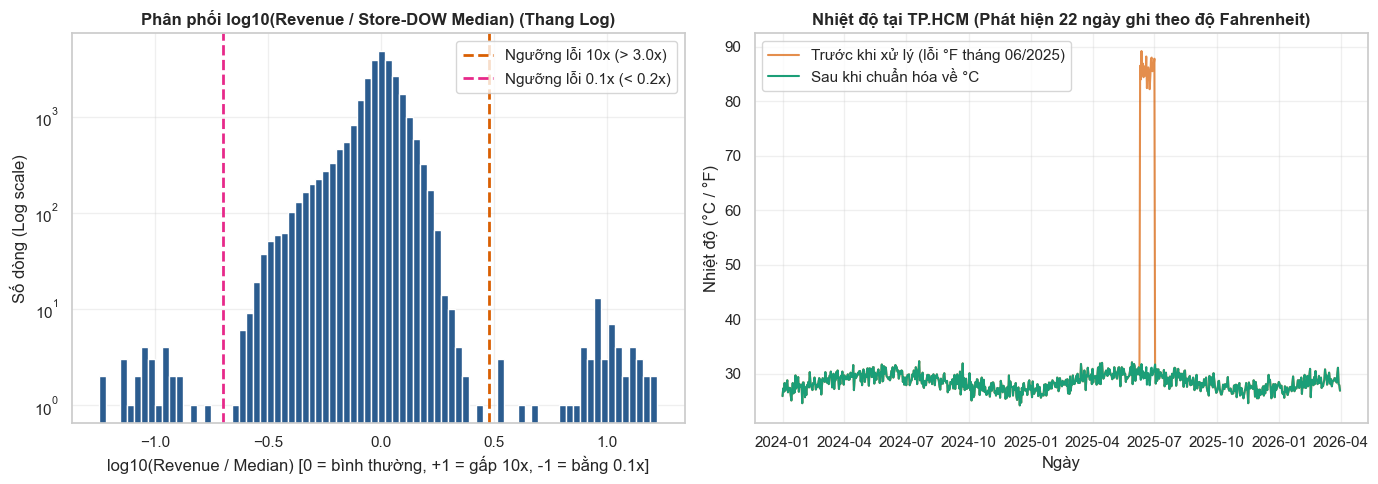

In [4]:
# Biểu đồ 1: Dị biệt doanh thu (train.csv) và Dị biệt nhiệt độ Fahrenheit (weather.csv)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: Tỷ lệ revenue / median_dow trước khi sửa lỗi 10x và 0.1x
tmp_raw = train_raw.drop_duplicates(subset=["date", "store_id"]).copy()
tmp_raw.loc[tmp_raw["revenue"] > 1000, "revenue"] /= 1000.0
tmp_raw["dow"] = tmp_raw["date"].dt.dayofweek
tmp_raw["med_dow"] = tmp_raw.groupby(["store_id", "dow"])["revenue"].transform("median")
tmp_raw["ratio_dow"] = tmp_raw["revenue"] / tmp_raw["med_dow"]

axes[0].hist(np.log10(tmp_raw["ratio_dow"]), bins=80, color="#2b5c8f", edgecolor="white")
axes[0].axvline(np.log10(3.0), color="#d95f02", linestyle="--", linewidth=2, label="Ngưỡng lỗi 10x (> 3.0x)")
axes[0].axvline(np.log10(0.20), color="#e7298a", linestyle="--", linewidth=2, label="Ngưỡng lỗi 0.1x (< 0.2x)")
axes[0].set_yscale("log")
axes[0].set_title("Phân phối log10(Revenue / Store-DOW Median) (Thang Log)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("log10(Revenue / Median) [0 = bình thường, +1 = gấp 10x, -1 = bằng 0.1x]")
axes[0].set_ylabel("Số dòng (Log scale)")
axes[0].legend()

# Panel B: Nhiệt độ TP.HCM trước và sau khi sửa lỗi độ F
hcm_raw = weather_raw[weather_raw["city"] == "Ho Chi Minh"].sort_values("date")
hcm_clean = weather_c[weather_c["city"] == "Ho Chi Minh"].sort_values("date")
axes[1].plot(hcm_raw["date"], hcm_raw["temp_c"], color="#d95f02", alpha=0.7, label="Trước khi xử lý (lỗi °F tháng 06/2025)")
axes[1].plot(hcm_clean["date"], hcm_clean["temp_c"], color="#1b9e77", linewidth=1.5, label="Sau khi chuẩn hóa về °C")
axes[1].set_title("Nhiệt độ tại TP.HCM (Phát hiện 22 ngày ghi theo độ Fahrenheit)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Ngày")
axes[1].set_ylabel("Nhiệt độ (°C / °F)")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "fig1_anomalies.png"), dpi=150)
plt.show()

---
## 2. Phân tích Hệ thống Cửa hàng (`stores.csv`)

Sau khi chuẩn hóa, chuỗi gồm **45 cửa hàng** tại 2 thành phố (**Hà Nội: 24 cửa hàng**, **TP.HCM: 21 cửa hàng**), chia thành 5 loại hình (`store_type`):
- `street` (15 cửa hàng), `office` (11 cửa hàng), `mall` (8 cửa hàng), `university` (6 cửa hàng), `residential` (5 cửa hàng).
- **Trạng thái hoạt động**: Có **1 cửa hàng đã đóng cửa** là `S02` (Thanh Xuân, Hà Nội — dữ liệu dừng từ sau ngày `14/08/2025`). Toàn bộ 44 cửa hàng còn lại hoạt động xuyên suốt sang Q1/2026.
- **Tương quan quy mô cửa hàng**: Số ghế (`seats`) và diện tích (`area_m2`) có tương quan tuyến tính rất chặt ($r = 0.934$), và `seats` tương quan mạnh với doanh thu cơ sở của cửa hàng ($r = 0.614$ trên thang log). Với cùng diện tích/số ghế, cửa hàng trong `mall` có doanh thu trên mỗi ghế cao nhất, tiếp theo là `street` và `office`, trong khi `university` và `residential` có mức giá/doanh thu trên mỗi ghế thấp hơn.

In [5]:
# Tổng hợp doanh thu trưởng thành trung bình của từng cửa hàng
df_full = train_c.merge(stores_c, on="store_id").merge(weather_c, on=["date", "city"])
df_full["log_rev"] = np.log1p(df_full["revenue"])

mature_normal = df_full[(df_full["days_since_open"] > 60) & (df_full["is_promo"] == 0) & (~df_full["date"].dt.month.isin([1, 2, 7, 8]))]
store_summary = mature_normal.groupby("store_id")["revenue"].agg(["count", "mean", "median", "std"]).reset_index()
store_summary = stores_c.merge(store_summary, on="store_id", how="left")

print("Thống kê theo loại hình cửa hàng (store_type) và thành phố (city):")
print(store_summary.groupby(["store_type", "city"]).agg(
    n_stores=("store_id", "count"),
    avg_area=("area_m2", "mean"),
    avg_seats=("seats", "mean"),
    avg_mature_rev=("mean", "mean")
).round(2))

Thống kê theo loại hình cửa hàng (store_type) và thành phố (city):
                         n_stores  avg_area  avg_seats  avg_mature_rev
store_type  city                                                      
mall        Ha Noi              4     98.25      33.25           18.96
            Ho Chi Minh         4     98.00      38.00           25.58
office      Ha Noi              5    126.82      47.40           17.63
            Ho Chi Minh         6    114.83      39.50           16.16
residential Ha Noi              3     79.67      27.33            7.16
            Ho Chi Minh         2     75.00      35.00           12.94
street      Ha Noi              9    155.36      63.56           22.66
            Ho Chi Minh         6    167.33      65.00           23.71
university  Ha Noi              3    170.00      64.67           13.83
            Ho Chi Minh         3    183.00      61.33           17.61


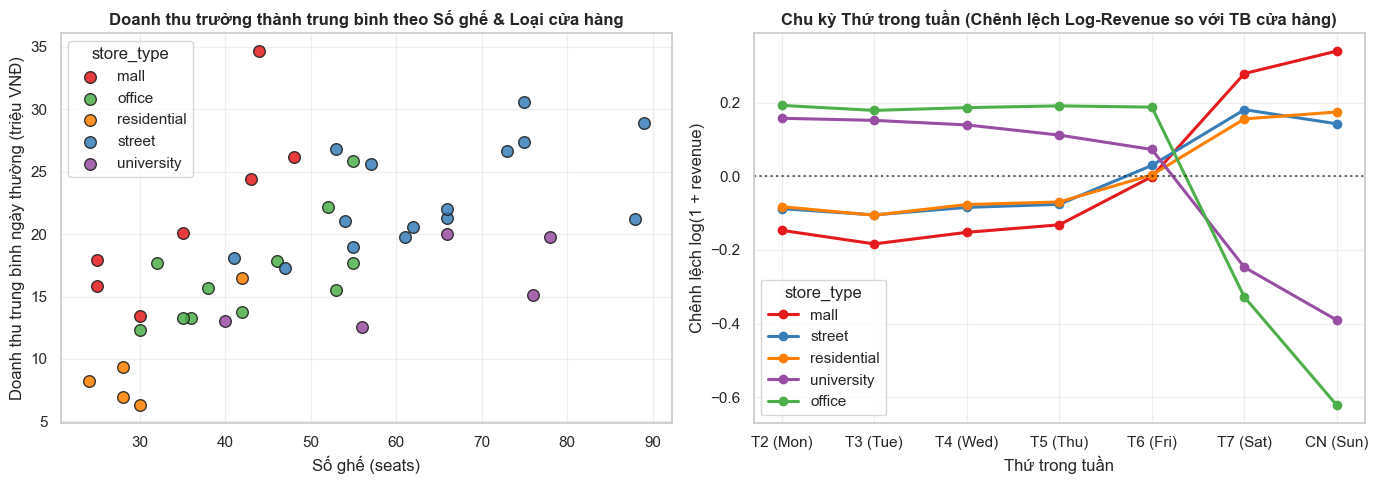

In [6]:
# Biểu đồ 2: Mối quan hệ giữa Số ghế (seats), Loại cửa hàng (store_type) và Chu kỳ Thứ trong tuần (DOW)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

palette = {"mall": "#e41a1c", "street": "#377eb8", "office": "#4daf4a", "university": "#984ea3", "residential": "#ff7f00"}
for st_type, grp in store_summary.dropna(subset=["mean"]).groupby("store_type"):
    axes[0].scatter(grp["seats"], grp["mean"], label=st_type, s=70, alpha=0.85, color=palette[st_type], edgecolors="k")
axes[0].set_title("Doanh thu trưởng thành trung bình theo Số ghế & Loại cửa hàng", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Số ghế (seats)")
axes[0].set_ylabel("Doanh thu trung bình ngày thường (triệu VNĐ)")
axes[0].legend(title="store_type")

# Panel B: Chu kỳ ngày trong tuần (Day of Week) theo store_type
df_full["store_mean_log"] = df_full.groupby("store_id")["log_rev"].transform("mean")
df_full["rel_log_rev"] = df_full["log_rev"] - df_full["store_mean_log"]
dow_piv = df_full.pivot_table(index="dow", columns="store_type", values="rel_log_rev", aggfunc="mean")
dow_names = ["T2 (Mon)", "T3 (Tue)", "T4 (Wed)", "T5 (Thu)", "T6 (Fri)", "T7 (Sat)", "CN (Sun)"]

for st_type in ["mall", "street", "residential", "university", "office"]:
    axes[1].plot(range(7), dow_piv[st_type], marker="o", linewidth=2.2, label=st_type, color=palette[st_type])
axes[1].axhline(0, color="black", linestyle=":", alpha=0.6)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(dow_names)
axes[1].set_title("Chu kỳ Thứ trong tuần (Chênh lệch Log-Revenue so với TB cửa hàng)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Thứ trong tuần")
axes[1].set_ylabel("Chênh lệch log(1 + revenue)")
axes[1].legend(title="store_type")

plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "fig2_store_types_dow.png"), dpi=150)
plt.show()

---
## 3. Vòng đời cửa hàng mới mở (`days_since_open`: Hiệu ứng Khai trương & 60 ngày chạy đà)

Có **11 cửa hàng** khai trương trong giai đoạn 2024–2025 (`S42, S43` năm 2024; `S09, S41, S44, S08, S07, S11, S19, S01, S45` năm 2025). Khi so sánh doanh thu những ngày đầu mở cửa với mức doanh thu trưởng thành (`days_since_open > 90`) của chính cửa hàng đó, ta phát hiện quy luật rất rõ ràng:
- **Ngày `0, 1, 2` (3 ngày khai trương đầu tiên)**: Doanh thu tăng đột biến **`+30%` đến `+46%`** trên thang log (kèm khuyến mãi khai trương).
- **Từ ngày thứ `3` đến ngày thứ `62` (60 ngày chạy đà — Ramp-up phase)**: Ngay sau 3 ngày khai trương, lượng khách vãng lai giảm về mức **`~55%`** công suất trưởng thành (`-0.60` trên thang log ở ngày thứ 3), sau đó **tăng trưởng tuyến tính đều đặn suốt 60 ngày** (`+0.01` log-revenue mỗi ngày) cho tới khi đạt `100%` mức ổn định từ ngày thứ `63` trở đi.
- **Ý nghĩa dự báo**: Hai cửa hàng `S01` (mở `07/12/2025`) và `S45` (mở `11/12/2025`) chỉ mới đi qua 20–24 ngày đầu tiên khi kết thúc tập `train.csv` (`31/12/2025`). Nếu chỉ lấy trung bình lịch sử tháng 12/2025 mà không khử hiệu ứng chạy đà, mô hình sẽ dự báo thấp hơn thực tế tới **35–40%** cho `S01` và `S45` trong Q1/2026.

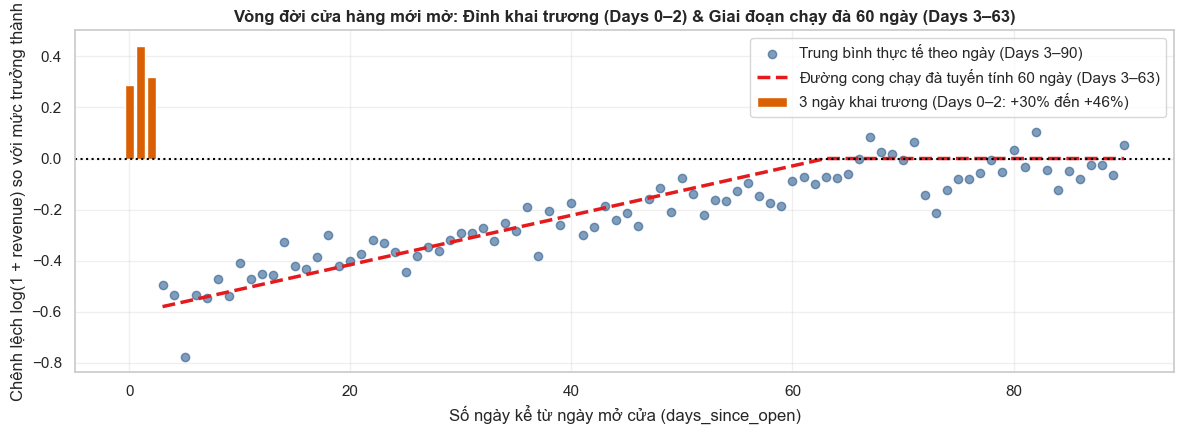

In [7]:
# Phân tích đường cong chạy đà (Ramp-up curve) theo days_since_open
mature_dow_base = (
    df_full[(df_full["days_since_open"] > 90) & (df_full["is_promo"] == 0) & (~df_full["date"].dt.month.isin([1, 2, 7, 8]))]
    .groupby(["store_id", "dow"])["log_rev"].mean().rename("mature_log_rev")
)
ramp_df = df_full.merge(mature_dow_base, on=["store_id", "dow"], how="inner")
ramp_df["net_diff"] = ramp_df["log_rev"] - ramp_df["mature_log_rev"] - ramp_df["is_promo"] * 0.25
ramp_curve = ramp_df[ramp_df["days_since_open"].between(0, 90)].groupby("days_since_open")["net_diff"].agg(["count", "mean", "median"])

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(ramp_curve.index[:3], ramp_curve["mean"].iloc[:3], color="#d95f02", width=0.8, label="3 ngày khai trương (Days 0–2: +30% đến +46%)")
ax.scatter(ramp_curve.index[3:], ramp_curve["mean"].iloc[3:], color="#2b5c8f", alpha=0.6, label="Trung bình thực tế theo ngày (Days 3–90)")
x_line = np.arange(3, 91)
y_line = -0.58 * np.clip(63 - x_line, 0, 60) / 60.0
ax.plot(x_line, y_line, color="#e41a1c", linewidth=2.5, linestyle="--", label="Đường cong chạy đà tuyến tính 60 ngày (Days 3–63)")
ax.axhline(0, color="black", linestyle=":")
ax.set_title("Vòng đời cửa hàng mới mở: Đỉnh khai trương (Days 0–2) & Giai đoạn chạy đà 60 ngày (Days 3–63)", fontsize=12, fontweight="bold")
ax.set_xlabel("Số ngày kể từ ngày mở cửa (days_since_open)")
ax.set_ylabel("Chênh lệch log(1 + revenue) so với mức trưởng thành")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "fig3_new_store_lifecycle.png"), dpi=150)
plt.show()

---
## 4. Phân tích Tết Nguyên Đán (`tet_offset`), Ngày lễ Quốc gia & Sự kiện (`holidays.csv`)

Tập dự báo `test.csv` rơi vào **Quý 1 (`01/01/2026 – 31/03/2026`)**, giai đoạn có **Tết Nguyên Đán** (Mùng 1 Tết là `17/02/2026`). Phân tích khoảng cách ngày so với Mùng 1 Tết (`tet_offset = (date - tet_date).days`) cho thấy mỗi loại cửa hàng phản ứng hoàn toàn khác nhau:
1. **`university` (6 cửa hàng)**: Sinh viên nghỉ Tết sớm từ **14 ngày trước Tết** đến hết **12 ngày sau Tết** (`tet_offset` $\in [-14, +12]$), làm doanh thu giảm sâu `-55%` (thang log) xuyên suốt 27 ngày và **đóng cửa hoàn toàn 6 ngày** từ 28 Tết đến Mùng 4 Tết (`[-2, +3]`).
2. **`office` (11 cửa hàng)**: **Đóng cửa hoàn toàn 5 ngày** từ 28 Tết đến Mùng 3 Tết (`[-2, +2]`). Từ Mùng 4 đến Mùng 10 Tết (`[+3, +9]`), nhiều nhân viên văn phòng còn nghỉ phép nên doanh thu giảm `-45%` trước khi trở lại bình thường từ `tet_offset = +10`.
3. **`mall` (8 cửa hàng)**: Tăng mạnh **`+15%` đến `+40%`** trong 10 ngày sắm Tết (`[-12, -3]`, đạt đỉnh vào ngày **23 Tết Ông Công Ông Táo** `tet_offset = -7`), giảm `-60%` trong 4 ngày Tết chính (`[-2, +1]`), và **phục hồi hoàn toàn ngay từ Mùng 3 Tết (`tet_offset = +2`)** nhờ khách đi chơi xuân tại trung tâm thương mại.
4. **`street` & `residential` (20 cửa hàng)**: Tăng nhẹ trước Tết (`[-10, -3]`), giảm sâu `-90%` (thang log) trong 5 ngày `[-2, +2]`, giảm nhẹ `-23%` trong các ngày `[+3, +7]`, và bình thường trở lại từ `+8`.
5. **Các ngày lễ Quốc gia khác (`New Year's Day`, `Hung Kings' Day`, `30/4`, `1/5`, `2/9`)**: Khi rơi vào ngày trong tuần, hành vi giống hệt ngày Chủ Nhật (`office` giảm `-70%`, `university` giảm `-50%`, trong khi `mall`, `street`, `residential` tăng `+15%` đến `+35%`).
6. **Các ngày sự kiện (`Valentine's Day 14/2`, `Women's Day 8/3`, `20/10`, `20/11`, `Christmas Eve 24/12`)**: Doanh thu tăng đồng loạt ở mọi loại hình cửa hàng (`+10%` đến `+28%`), đặc biệt cao ở `mall`, `street` và `university`.

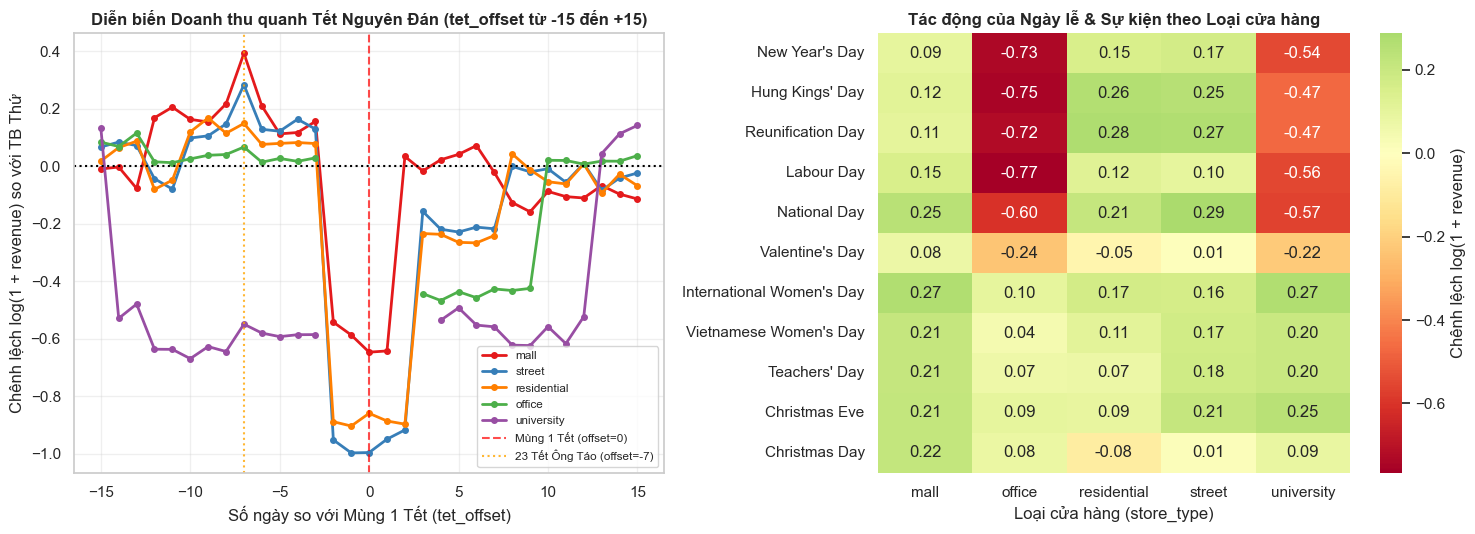

In [8]:
# Biểu đồ 4: Chu kỳ Tết Nguyên Đán (-15 đến +15) và Tác động của các ngày lễ / sự kiện
df_full["store_dow_mean"] = df_full.groupby(["store_id", "dow"])["log_rev"].transform("mean")
df_full["res_dow"] = df_full["log_rev"] - df_full["store_dow_mean"]
df_full["tet_offset"] = (df_full["date"] - df_full["date"].dt.year.map(tet_dates)).dt.days

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

tet_piv = df_full[df_full["tet_offset"].between(-15, 15)].pivot_table(index="tet_offset", columns="store_type", values="res_dow", aggfunc="mean")
for st_type in ["mall", "street", "residential", "office", "university"]:
    axes[0].plot(tet_piv.index, tet_piv[st_type], marker="o", markersize=4, linewidth=2, label=st_type, color=palette[st_type])
axes[0].axvline(0, color="red", linestyle="--", alpha=0.7, label="Mùng 1 Tết (offset=0)")
axes[0].axvline(-7, color="orange", linestyle=":", alpha=0.8, label="23 Tết Ông Táo (offset=-7)")
axes[0].axhline(0, color="black", linestyle=":")
axes[0].set_title("Diễn biến Doanh thu quanh Tết Nguyên Đán (tet_offset từ -15 đến +15)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Số ngày so với Mùng 1 Tết (tet_offset)")
axes[0].set_ylabel("Chênh lệch log(1 + revenue) so với TB Thứ")
axes[0].legend(fontsize=8.5)

# Panel B: Các ngày lễ & sự kiện ngoài Tết
hol_dedup = holidays_raw[~holidays_raw["holiday_name"].str.contains("Tet")].groupby("date").first().reset_index()
df_hol = df_full.merge(hol_dedup, on="date", how="inner")
hol_piv = df_hol.pivot_table(index="holiday_name", columns="store_type", values="res_dow", aggfunc="mean")
hol_order = ["New Year's Day", "Hung Kings' Day", "Reunification Day", "Labour Day", "National Day", "Valentine's Day", "International Women's Day", "Vietnamese Women's Day", "Teachers' Day", "Christmas Eve", "Christmas Day"]
hol_piv = hol_piv.reindex([h for h in hol_order if h in hol_piv.index])
sns.heatmap(hol_piv, annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=axes[1], cbar_kws={"label": "Chênh lệch log(1 + revenue)"})
axes[1].set_title("Tác động của Ngày lễ & Sự kiện theo Loại cửa hàng", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Loại cửa hàng (store_type)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "fig4_tet_and_holidays.png"), dpi=150)
plt.show()

---
## 5. Tính mùa vụ (Kỳ nghỉ hè Đại học) & Xu hướng tăng trưởng theo thời gian

Phân tích chuỗi thời gian theo tháng từ 2024 đến hết 2025 cho thấy:
1. **Kỳ nghỉ hè của khối `university` (Tháng 7 & Tháng 8)**: Doanh thu của toàn bộ các quán cafe trường đại học giảm trung bình **`-0.415` trên thang log** (tương đương giảm `~34%` doanh thu) từ ngày `01/07` đến `31/08` hàng năm, và bật tăng trở lại ngay từ ngày `04/09` khi bước vào năm học mới.
2. **Xu hướng tăng trưởng tự nhiên (Secular Trend)**: Đối với các cửa hàng đã hoạt động ổn định trước năm 2024, doanh thu trung bình năm 2025 tăng khoảng **`+6%` đến `+7%`** so với cùng kỳ năm 2024.
3. **Hiệu ứng khuyến mãi (`is_promo = 1`)**: Chiếm `11.4%` số ngày hoạt động và giúp tăng đồng đều **`+0.25` đến `+0.27` log-revenue** (`~28–30%` doanh thu) trên tất cả các loại cửa hàng.

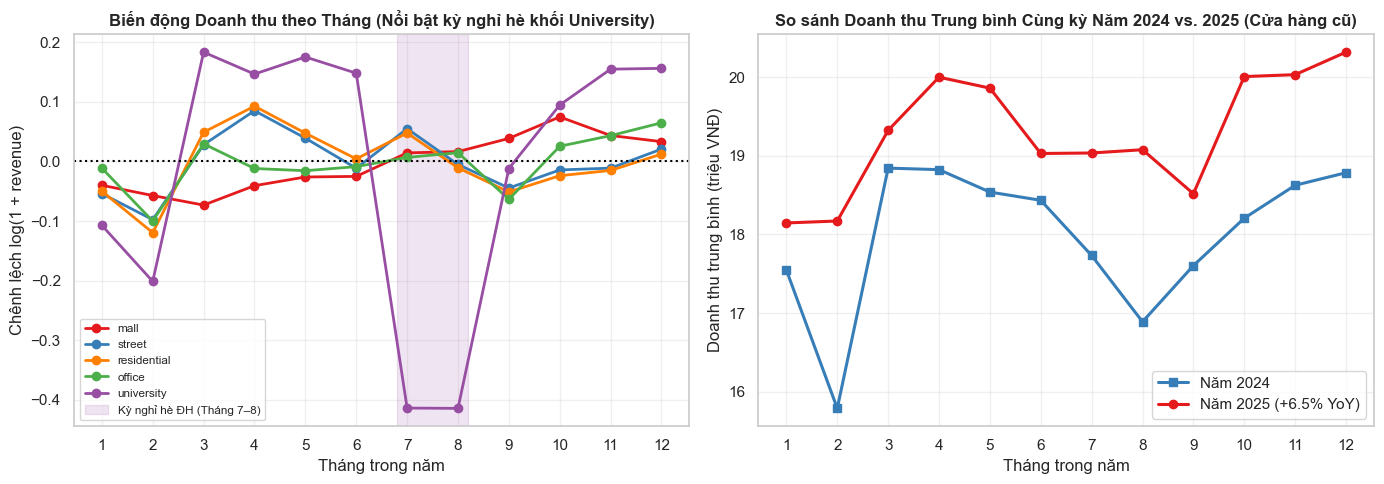

In [9]:
# Biểu đồ 5: Tính mùa vụ theo tháng (Kỳ nghỉ hè đại học) và Tăng trưởng 2024 vs 2025
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_full["month"] = df_full["date"].dt.month
month_piv = df_full.pivot_table(index="month", columns="store_type", values="res_dow", aggfunc="mean")
for st_type in ["mall", "street", "residential", "office", "university"]:
    axes[0].plot(month_piv.index, month_piv[st_type], marker="o", linewidth=2, label=st_type, color=palette[st_type])
axes[0].axvspan(6.8, 8.2, color="#984ea3", alpha=0.15, label="Kỳ nghỉ hè ĐH (Tháng 7–8)")
axes[0].axhline(0, color="black", linestyle=":")
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Biến động Doanh thu theo Tháng (Nổi bật kỳ nghỉ hè khối University)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Tháng trong năm")
axes[0].set_ylabel("Chênh lệch log(1 + revenue)")
axes[0].legend(fontsize=8.5)

# Panel B: Tăng trưởng YoY (2024 vs 2025) trên nhóm cửa hàng mở trước 2024
old_stores = df_full[df_full["open_date"] < "2023-10-01"].copy()
old_stores["year"] = old_stores["date"].dt.year
yoy_piv = old_stores.pivot_table(index="month", columns="year", values="revenue", aggfunc="mean")
axes[1].plot(yoy_piv.index, yoy_piv[2024], marker="s", linewidth=2.2, color="#377eb8", label="Năm 2024")
axes[1].plot(yoy_piv.index, yoy_piv[2025], marker="o", linewidth=2.2, color="#e41a1c", label="Năm 2025 (+6.5% YoY)")
axes[1].set_xticks(range(1, 13))
axes[1].set_title("So sánh Doanh thu Trung bình Cùng kỳ Năm 2024 vs. 2025 (Cửa hàng cũ)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tháng trong năm")
axes[1].set_ylabel("Doanh thu trung bình (triệu VNĐ)")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "fig5_seasonality_university.png"), dpi=150)
plt.show()

---
## 6. Phân tích Tác động của Thời tiết (`weather.csv`: Lượng mưa & Nhiệt độ)

Sau khi loại bỏ hiệu ứng thứ trong tuần, khuyến mãi, kỳ nghỉ hè và Tết, phân tích phần dư theo thời tiết cho thấy:
1. **Tác động trái chiều của lượng mưa (`rain_mm`) theo không gian quán**:
   - Khi mưa vừa (`10–30 mm`) và mưa to (`> 30 mm`), các quán phụ thuộc mặt tiền/di chuyển ngoài trời gồm `street`, `university` và `residential` giảm mạnh từ **`-8%` đến `-41%`** (thang log). Quán `office` chỉ giảm nhẹ (`-2%` đến `-14%`).
   - Ngược lại, quán trong trung tâm thương mại (**`mall`**) **tăng nhẹ `+2.5%` đến `+3.7%`** khi trời mưa do khách hàng ưu tiên không gian mua sắm trong nhà.
2. **Tác động của nhiệt độ (`temp_c`)**:
   - Tại **Hà Nội** (biên độ nhiệt rộng `12.2 °C – 35.6 °C`): những ngày trời rét đậm (`< 18 °C`), doanh thu các quán `street` và `residential` giảm khoảng `-5%` đến `-7%` so với những ngày thời tiết ấm áp (`22–30 °C`).
   - Tại **TP.HCM** (nhiệt độ ổn định `24.2 °C – 32.3 °C`): những ngày nắng nóng (`> 29.5 °C`), nhu cầu giải khát tại các quán `street`, `residential`, `university` tăng `+3%` đến `+6%`.

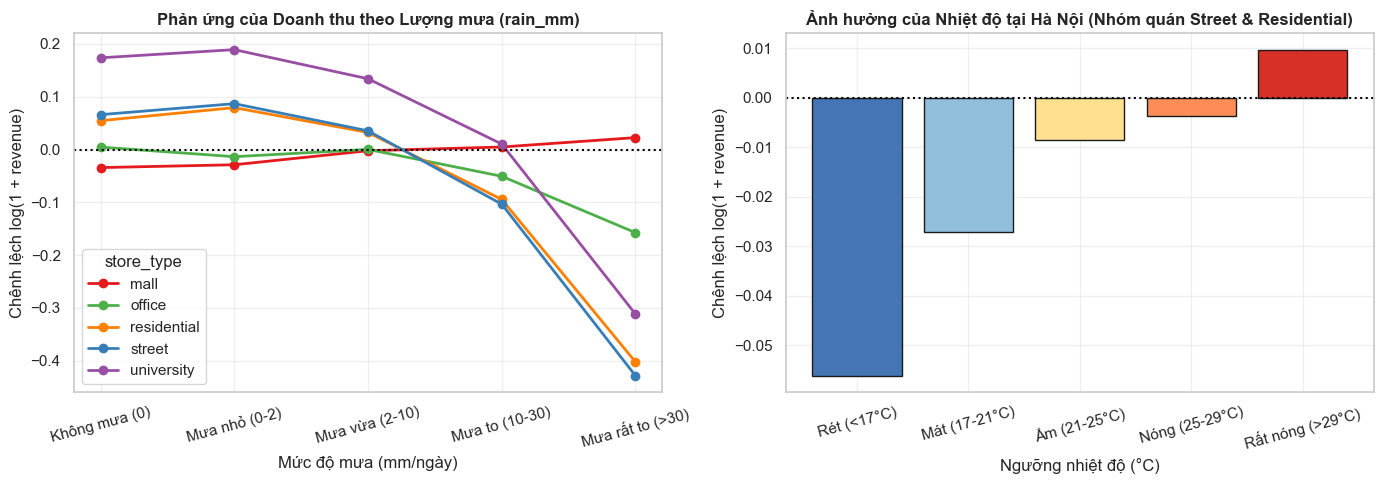

In [10]:
# Biểu đồ 6: Tác động của Lượng mưa (rain_mm) và Nhiệt độ (temp_c)
normal_days = df_full[
    (df_full["days_since_open"] > 60)
    & (df_full["is_promo"] == 0)
    & (~df_full["tet_offset"].between(-14, 12))
    & (~((df_full["store_type"] == "university") & (df_full["month"].isin([7, 8]))))
].copy()

normal_days["rain_group"] = pd.cut(
    normal_days["rain_mm"],
    bins=[-0.1, 0.0, 2.0, 10.0, 30.0, 200.0],
    labels=["Không mưa (0)", "Mưa nhỏ (0-2)", "Mưa vừa (2-10)", "Mưa to (10-30)", "Mưa rất to (>30)"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rain_piv = normal_days.pivot_table(index="rain_group", columns="store_type", values="res_dow", aggfunc="mean", observed=False)
for st_type in ["mall", "office", "residential", "street", "university"]:
    axes[0].plot(range(len(rain_piv)), rain_piv[st_type], marker="o", linewidth=2, label=st_type, color=palette[st_type])
axes[0].axhline(0, color="black", linestyle=":")
axes[0].set_xticks(range(len(rain_piv)))
axes[0].set_xticklabels(rain_piv.index, rotation=15)
axes[0].set_title("Phản ứng của Doanh thu theo Lượng mưa (rain_mm)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Mức độ mưa (mm/ngày)")
axes[0].set_ylabel("Chênh lệch log(1 + revenue)")
axes[0].legend(title="store_type")

# Panel B: Nhiệt độ tại Hà Nội trên nhóm cửa hàng ngoài trời (street & residential)
hn_outdoor = normal_days[(normal_days["city"] == "Ha Noi") & (normal_days["store_type"].isin(["street", "residential"]))].copy()
hn_outdoor["temp_bin"] = pd.cut(hn_outdoor["temp_c"], bins=[10, 17, 21, 25, 29, 36], labels=["Rét (<17°C)", "Mát (17-21°C)", "Ấm (21-25°C)", "Nóng (25-29°C)", "Rất nóng (>29°C)"])
temp_piv = hn_outdoor.groupby("temp_bin", observed=False)["res_dow"].mean()
axes[1].bar(range(len(temp_piv)), temp_piv.values, color=["#4575b4", "#91bfdb", "#fee090", "#fc8d59", "#d73027"], edgecolor="k")
axes[1].axhline(0, color="black", linestyle=":")
axes[1].set_xticks(range(len(temp_piv)))
axes[1].set_xticklabels(temp_piv.index, rotation=15)
axes[1].set_title("Ảnh hưởng của Nhiệt độ tại Hà Nội (Nhóm quán Street & Residential)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Ngưỡng nhiệt độ (°C)")
axes[1].set_ylabel("Chênh lệch log(1 + revenue)")

plt.tight_layout()
plt.savefig(os.path.join(ART_DIR, "fig6_weather_impact.png"), dpi=150)
plt.show()